# Week 8: K-Nearest Neighbors (KNN)
## Marketing Conversion Propensity

Applies the K-Nearest Neighbor Classification Algorithm on three datasets related to marketing to analyze the relationship between customer engagement, marketing campaigns’ effectiveness, and business activities with marketing results. Utilizes two kinds of distance measures such as Euclidean and Manhattan, along with different values of k.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)
pd.set_option("display.max_columns", None)


In [4]:
df1 = pd.read_csv("digital_marketing_campaign_dataset.csv")
df2 = pd.read_csv("marketing_and_product_performance.csv")
df3 = pd.read_csv("companies_clean_734.csv")

print("Digital Marketing Campaign:", df1.shape)
print("Marketing and Product Performance:", df2.shape)
print("Synthetic B2B CRM & Marketing Dataset:", df3.shape)

Digital Marketing Campaign: (8000, 20)
Marketing and Product Performance: (10000, 17)
Synthetic B2B CRM & Marketing Dataset: (734, 19)


## Dataset 1: Digital Marketing Campaign

Conversion will be the dependent variable, which indicates conversion by the customers. Classification using K-Nearest Neighbors will be conducted using AdSpend, ClickThroughRate, WebsiteVisits, TimeOnSite, and EmailClicks. As the method used requires distance between data points, feature scaling will be conducted to prevent variables with higher numerical values from overshadowing the calculations.

In [5]:
features1 = ["AdSpend", "ClickThroughRate", "WebsiteVisits", "TimeOnSite", "EmailClicks"]

X1 = df1[features1]
y1 = df1["Conversion"]

X1_train, X1_test, y1_train, y1_test = train_test_split(
    X1, y1, test_size=0.2, random_state=42, stratify=y1
)

print("Training:", X1_train.shape)
print("Testing:", X1_test.shape)
print("\nTarget Distribution:")
print(y1.value_counts())

Training: (6400, 5)
Testing: (1600, 5)

Target Distribution:
Conversion
1    7012
0     988
Name: count, dtype: int64


### K-Nearest Neighbors: Euclidean Distance

KNN classifier will be developed using 5 nearest neighbors and Euclidean distance. The StandardScaler function will be used to ensure that all the predictors have an equal contribution when calculating distance. Evaluation metrics to be considered include accuracy, precision, recall, F1, and ROC-AUC.

In [6]:
knn1 = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier(n_neighbors=5, metric="euclidean"))
])

knn1.fit(X1_train, y1_train)

y1_pred = knn1.predict(X1_test)
y1_prob = knn1.predict_proba(X1_test)[:, 1]

print("KNN (Euclidean Distance, k=5)")
print("Accuracy:", round(accuracy_score(y1_test, y1_pred), 4))
print("Precision:", round(precision_score(y1_test, y1_pred), 4))
print("Recall:", round(recall_score(y1_test, y1_pred), 4))
print("F1 Score:", round(f1_score(y1_test, y1_pred), 4))
print("ROC-AUC:", round(roc_auc_score(y1_test, y1_prob), 4))
print("\nConfusion Matrix:")
print(confusion_matrix(y1_test, y1_pred))

KNN (Euclidean Distance, k=5)
Accuracy: 0.8656
Precision: 0.8882
Recall: 0.9686
F1 Score: 0.9266
ROC-AUC: 0.6529

Confusion Matrix:
[[  27  171]
 [  44 1358]]


Euclidean KNN with k = 5 obtained an accuracy rate of 86.56% and AUC-ROC value of 0.6529. Despite recall being very high at 96.86%, only 27 out of 198 non-conversions were correctly classified by this algorithm. This is evidence that KNN algorithm supports majority class more than the other class and is unable to differentiate between converting and non-converting clients. Additionally, its accuracy is below the majority class baseline of 87.65%.

### KNN Distance Metric Comparison

Euclidean and Manhattan distances will be analyzed with the help of five nearest neighbors. The analysis will find out if the use of different distances influences the results of classification and the distinction between conversion and non-conversion.

In [7]:
results1 = []

for metric in ["euclidean", "manhattan"]:
    model = Pipeline([
        ("scaler", StandardScaler()),
        ("knn", KNeighborsClassifier(n_neighbors=5, metric=metric))
    ])

    model.fit(X1_train, y1_train)

    y_pred = model.predict(X1_test)
    y_prob = model.predict_proba(X1_test)[:, 1]

    results1.append({
        "Distance": metric,
        "Accuracy": accuracy_score(y1_test, y_pred),
        "Precision": precision_score(y1_test, y_pred),
        "Recall": recall_score(y1_test, y_pred),
        "F1": f1_score(y1_test, y_pred),
        "ROC-AUC": roc_auc_score(y1_test, y_prob)
    })

results1_df = pd.DataFrame(results1)
print(results1_df.round(4).to_string(index=False))

 Distance  Accuracy  Precision  Recall     F1  ROC-AUC
euclidean    0.8656     0.8882  0.9686 0.9266   0.6529
manhattan    0.8662     0.8862  0.9722 0.9272   0.6372


The results obtained by both of these distance functions were similar. The accuracy of Manhattan distance was marginally higher at 86.62%, with an F1 score of 0.9272, whereas the ROC-AUC for Euclidean distance was 0.6529, which is marginally higher than that for Manhattan distance. This means that switching from one distance function to another had no major impact on accuracy; however, it did have an impact on class discrimination.

### KNN Neighbor Comparison

Various values for k will be tested using both Euclidean distance and Manhattan distance to see how the number of neighbors impacts classification. Accuracy and ROC-AUC will be compared in order to see if increasing or decreasing k makes a difference.

In [8]:
k_values = [1, 3, 5, 7, 9, 11, 15, 21, 31]
k_results1 = []

for metric in ["euclidean", "manhattan"]:
    for k in k_values:
        model = Pipeline([
            ("scaler", StandardScaler()),
            ("knn", KNeighborsClassifier(n_neighbors=k, metric=metric))
        ])

        model.fit(X1_train, y1_train)

        y_pred = model.predict(X1_test)
        y_prob = model.predict_proba(X1_test)[:, 1]

        k_results1.append({
            "Distance": metric,
            "K": k,
            "Accuracy": accuracy_score(y1_test, y_pred),
            "ROC-AUC": roc_auc_score(y1_test, y_prob)
        })

k_results1_df = pd.DataFrame(k_results1)

print(k_results1_df.round(4).to_string(index=False))

 Distance  K  Accuracy  ROC-AUC
euclidean  1    0.8150   0.5691
euclidean  3    0.8450   0.6326
euclidean  5    0.8656   0.6529
euclidean  7    0.8725   0.6691
euclidean  9    0.8750   0.6719
euclidean 11    0.8744   0.6875
euclidean 15    0.8756   0.6952
euclidean 21    0.8756   0.7005
euclidean 31    0.8806   0.7056
manhattan  1    0.8138   0.5728
manhattan  3    0.8425   0.6196
manhattan  5    0.8662   0.6372
manhattan  7    0.8719   0.6633
manhattan  9    0.8744   0.6740
manhattan 11    0.8750   0.6921
manhattan 15    0.8769   0.6937
manhattan 21    0.8762   0.6990
manhattan 31    0.8800   0.6982


The inclusion of more neighbors was beneficial for KNN for both distance measures. The maximum testing accuracy of 88.06% with a ROC-AUC of 0.7056 was obtained from the euclidean distance for k=31. For k=1, there was an accuracy of 81.50% with a ROC-AUC of 0.5691. This implies that using more neighbors decreased the sensitivity to individual cases while improving class separation. Nevertheless, the accuracy was almost at par with the majority class percentage of 87.65%.

### KNN Hyperparameter Tuning

Five folds of cross-validation using GridSearchCV will be applied in order to find the optimal number of neighbors and distance metric. ROC-AUC will be applied in order to choose the right model due to the imbalance of the target variable.

In [9]:
knn_grid1 = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier())
])

param_grid1 = {
    "knn__n_neighbors": [1, 3, 5, 7, 9, 11, 15, 21, 31],
    "knn__metric": ["euclidean", "manhattan"]
}

grid1 = GridSearchCV(
    knn_grid1,
    param_grid1,
    cv=5,
    scoring="roc_auc",
    n_jobs=-1
)

grid1.fit(X1_train, y1_train)

print("Best Parameters:", grid1.best_params_)
print("Best Cross-Validation ROC-AUC:", round(grid1.best_score_, 4))

best_knn1 = grid1.best_estimator_

y1_pred_tuned = best_knn1.predict(X1_test)
y1_prob_tuned = best_knn1.predict_proba(X1_test)[:, 1]

print("\nTuned KNN Testing Results:")
print("Accuracy:", round(accuracy_score(y1_test, y1_pred_tuned), 4))
print("Precision:", round(precision_score(y1_test, y1_pred_tuned), 4))
print("Recall:", round(recall_score(y1_test, y1_pred_tuned), 4))
print("F1 Score:", round(f1_score(y1_test, y1_pred_tuned), 4))
print("ROC-AUC:", round(roc_auc_score(y1_test, y1_prob_tuned), 4))
print("\nConfusion Matrix:")
print(confusion_matrix(y1_test, y1_pred_tuned))

Best Parameters: {'knn__metric': 'euclidean', 'knn__n_neighbors': 31}
Best Cross-Validation ROC-AUC: 0.7112

Tuned KNN Testing Results:
Accuracy: 0.8806
Precision: 0.8825
Recall: 0.9964
F1 Score: 0.936
ROC-AUC: 0.7056

Confusion Matrix:
[[  12  186]
 [   5 1397]]


The results obtained from GridSearchCV indicate that the optimal parameters are Euclidean distance and k=31, having achieved 0.7112 and 0.7056 cross-validation and testing ROC-AUC respectively. The testing accuracy was increased to 88.06%, as opposed to 86.56% when using the original model of k=5. From the confusion matrix, it can be seen that out of the 198 non-conversion, only 12 were predicted correctly.

### KNN Performance Visualization

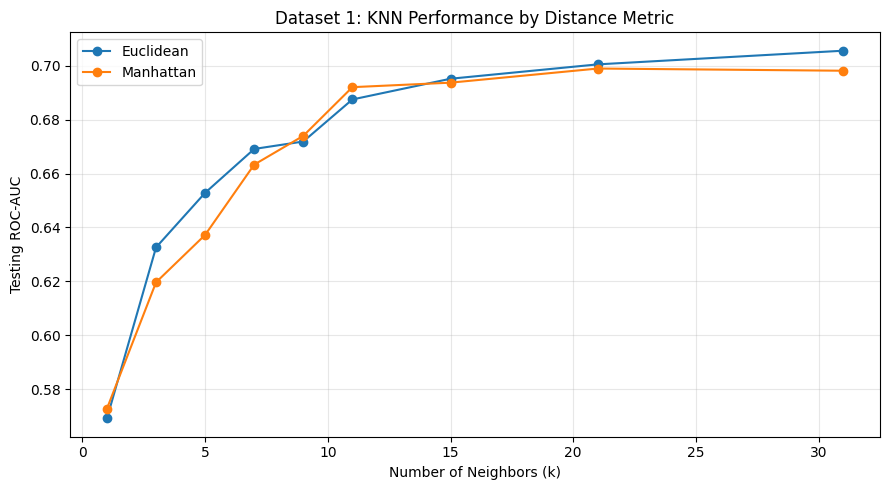

In [10]:
plt.figure(figsize=(9, 5))

for metric in ["euclidean", "manhattan"]:
    subset = k_results1_df[k_results1_df["Distance"] == metric]
    plt.plot(
        subset["K"],
        subset["ROC-AUC"],
        marker="o",
        label=metric.capitalize()
    )

plt.xlabel("Number of Neighbors (k)")
plt.ylabel("Testing ROC-AUC")
plt.title("Dataset 1: KNN Performance by Distance Metric")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Dataset 1 Conclusion

Performance of K-Nearest Neighbors was better when more neighbors were used. Tuned K-NN model with Euclidean distance metric and k = 31 resulted in an accuracy rate of 88.06% and ROC-AUC value of 0.7056, which is higher than that of the baseline k = 5 model. Cross-validation led to a ROC-AUC score of 0.7112. However, the model could detect 12 out of 198 non-converters, which indicates that the problem associated with imbalance in the target variable still exists.

## Dataset 2: Marketing and Product Performance

Target variable will be high_ROI, which indicates if the campaign was successful and achieved an ROI greater than the median ROI value of the data set. The KNN algorithm will be applied to categorize the campaign into classes using budget, clicks, conversions, units_sold, and bundle price as the features.

In [11]:
df2["High_ROI"] = (df2["ROI"] > df2["ROI"].median()).astype(int)

features2 = ["Budget", "Clicks", "Conversions", "Units_Sold", "Bundle_Price"]
X2 = df2[features2]
y2 = df2["High_ROI"]
X2_train, X2_test, y2_train, y2_test = train_test_split(
    X2, y2, test_size=0.2, random_state=42, stratify=y2
)

print("Training:", X2_train.shape)
print("Testing:", X2_test.shape)
print("\nTarget Distribution:")
print(y2.value_counts())

Training: (8000, 5)
Testing: (2000, 5)

Target Distribution:
High_ROI
0    5002
1    4998
Name: count, dtype: int64


### K-Nearest Neighbors: Euclidean Distance

In [12]:
knn2 = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier(n_neighbors=5, metric="euclidean"))
])

knn2.fit(X2_train, y2_train)

y2_pred = knn2.predict(X2_test)
y2_prob = knn2.predict_proba(X2_test)[:, 1]

print("KNN (Euclidean Distance, k=5)")
print("Accuracy:", round(accuracy_score(y2_test, y2_pred), 4))
print("Precision:", round(precision_score(y2_test, y2_pred), 4))
print("Recall:", round(recall_score(y2_test, y2_pred), 4))
print("F1 Score:", round(f1_score(y2_test, y2_pred), 4))
print("ROC-AUC:", round(roc_auc_score(y2_test, y2_prob), 4))
print("\nConfusion Matrix:")
print(confusion_matrix(y2_test, y2_pred))

KNN (Euclidean Distance, k=5)
Accuracy: 0.495
Precision: 0.4948
Recall: 0.475
F1 Score: 0.4847
ROC-AUC: 0.5027

Confusion Matrix:
[[515 485]
 [525 475]]


For the KNN algorithm with Euclidean distance and k = 5, the accuracy was 49.50%, and the ROC-AUC was 0.5027. From the confusion matrix, it is clear that 515 campaigns with low ROI and 475 campaigns with high ROI have been classified accurately, whereas 1,010 campaigns have been misclassified. As a result of the balanced target distribution, it can be deduced that the model performed as well as random guessing.

### KNN Distance Metric Comparison

In [13]:
results2 = []

for metric in ["euclidean", "manhattan"]:
    model = Pipeline([
        ("scaler", StandardScaler()),
        ("knn", KNeighborsClassifier(n_neighbors=5, metric=metric))
    ])

    model.fit(X2_train, y2_train)
    y_pred = model.predict(X2_test)
    y_prob = model.predict_proba(X2_test)[:, 1]

    results2.append({
        "Distance": metric,
        "Accuracy": accuracy_score(y2_test, y_pred),
        "Precision": precision_score(y2_test, y_pred),
        "Recall": recall_score(y2_test, y_pred),
        "F1": f1_score(y2_test, y_pred),
        "ROC-AUC": roc_auc_score(y2_test, y_prob)
    })

results2_df = pd.DataFrame(results2)
print(results2_df.round(4).to_string(index=False))

 Distance  Accuracy  Precision  Recall     F1  ROC-AUC
euclidean    0.4950     0.4948   0.475 0.4847   0.5027
manhattan    0.4975     0.4974   0.474 0.4854   0.4976


The two distance metrics gave very close performance levels. The Manhattan distance gave a slight edge in terms of accuracy of 49.75% with an F1 score of 0.4854. The Euclidean distance gave an ROC-AUC of 0.5027 as compared to 0.4976. There was no significant boost in prediction from using any of the two distance metrics.

### KNN Neighbor Comparison

In [14]:
k_values = [1, 3, 5, 7, 9, 11, 15, 21, 31]
k_results2 = []

for metric in ["euclidean", "manhattan"]:
    for k in k_values:
        model = Pipeline([
            ("scaler", StandardScaler()),
            ("knn", KNeighborsClassifier(n_neighbors=k, metric=metric))
        ])

        model.fit(X2_train, y2_train)
        y_pred = model.predict(X2_test)
        y_prob = model.predict_proba(X2_test)[:, 1]

        k_results2.append({
            "Distance": metric,
            "K": k,
            "Accuracy": accuracy_score(y2_test, y_pred),
            "ROC-AUC": roc_auc_score(y2_test, y_prob)
        })

k_results2_df = pd.DataFrame(k_results2)
print(k_results2_df.round(4).to_string(index=False))

 Distance  K  Accuracy  ROC-AUC
euclidean  1    0.5050   0.5050
euclidean  3    0.5030   0.5081
euclidean  5    0.4950   0.5027
euclidean  7    0.5015   0.4994
euclidean  9    0.5095   0.5023
euclidean 11    0.5080   0.4971
euclidean 15    0.4875   0.4919
euclidean 21    0.4920   0.4943
euclidean 31    0.4950   0.4889
manhattan  1    0.4985   0.4985
manhattan  3    0.5095   0.5097
manhattan  5    0.4975   0.4976
manhattan  7    0.4850   0.4987
manhattan  9    0.4845   0.4897
manhattan 11    0.4960   0.4927
manhattan 15    0.5040   0.4971
manhattan 21    0.4930   0.4925
manhattan 31    0.4900   0.4960


Modification of the number of neighbors brought insignificant changes in the performance of KNN model. The best accuracy of prediction in test data was 50.95% obtained by using Euclidean distance for k=9 and Manhattan distance for k=3. Also, Manhattan distance for k=3 obtained the highest ROC-AUC value of 0.5097. In contrast to Dataset 1, increase in the number of neighbors k did not bring any improvements. In general, the accuracy of the prediction was still similar to chance.

### KNN Hyperparameter Tuning

In [15]:
knn_grid2 = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier())
])

param_grid2 = {
    "knn__n_neighbors": [1, 3, 5, 7, 9, 11, 15, 21, 31],
    "knn__metric": ["euclidean", "manhattan"]
}

grid2 = GridSearchCV(
    knn_grid2,
    param_grid2,
    cv=5,
    scoring="roc_auc",
    n_jobs=-1
)

grid2.fit(X2_train, y2_train)

print("Best Parameters:", grid2.best_params_)
print("Best Cross-Validation ROC-AUC:", round(grid2.best_score_, 4))

best_knn2 = grid2.best_estimator_
y2_pred_tuned = best_knn2.predict(X2_test)
y2_prob_tuned = best_knn2.predict_proba(X2_test)[:, 1]

print("\nTuned KNN Testing Results:")
print("Accuracy:", round(accuracy_score(y2_test, y2_pred_tuned), 4))
print("Precision:", round(precision_score(y2_test, y2_pred_tuned), 4))
print("Recall:", round(recall_score(y2_test, y2_pred_tuned), 4))
print("F1 Score:", round(f1_score(y2_test, y2_pred_tuned), 4))
print("ROC-AUC:", round(roc_auc_score(y2_test, y2_prob_tuned), 4))
print("\nConfusion Matrix:")
print(confusion_matrix(y2_test, y2_pred_tuned))

Best Parameters: {'knn__metric': 'manhattan', 'knn__n_neighbors': 1}
Best Cross-Validation ROC-AUC: 0.505

Tuned KNN Testing Results:
Accuracy: 0.4985
Precision: 0.4985
Recall: 0.495
F1 Score: 0.4967
ROC-AUC: 0.4985

Confusion Matrix:
[[502 498]
 [505 495]]


The GridSearchCV model yielded a Manhattan Distance algorithm for k=1 with an ROC-AUC of 0.5050 for cross-validation and 0.4985 for the test set. Accuracy achieved during testing is 49.85% which means that there is no improvement on the initial model. Confusion matrix values indicate that 502 low ROI campaigns and 495 high ROI campaigns have been classified correctly while 1003 campaigns have been misclassified.

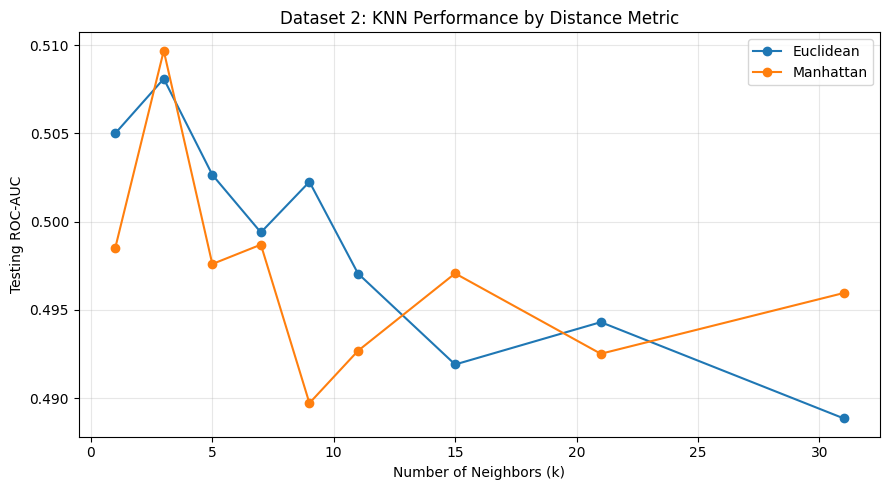

In [16]:
plt.figure(figsize=(9, 5))
for metric in ["euclidean", "manhattan"]:
    subset = k_results2_df[k_results2_df["Distance"] == metric]
    plt.plot(
        subset["K"],
        subset["ROC-AUC"],
        marker="o",
        label=metric.capitalize()
    )
plt.xlabel("Number of Neighbors (k)")
plt.ylabel("Testing ROC-AUC")
plt.title("Dataset 2: KNN Performance by Distance Metric")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Dataset 2 Conclusion

K-Nearest Neighbors showed poor prediction capability on the Marketing and Product Performance data set. With the model tuned with Manhattan distance and k=1, accuracy was obtained at 49.85%, while ROC-AUC was at 0.4985, showing near random performance. Though other distance measurements and number of neighbors were tried out, there were no significant changes in performance. In contrast to Dataset 1, increase in k values does not improve performance. KNN was ineffective in predicting the difference between high ROI and low ROI campaigns.

## Dataset 3: Synthetic B2B CRM & Marketing Dataset

Active_Contract is our target variable which shows whether the firm has an active contract or not. We will use the K-Nearest Neighbors algorithm for classification according to annual income, marketing expenses, days since last purchase, and number of purchases in the previous year. Performing feature scaling due to KNN’s distance calculations. The following metrics will be used to evaluate our model: Accuracy, Precision, Recall, F1-Score, and ROC-AUC.

In [17]:
df3["Active_Contract"] = (df3["Contract_Status"] == "Active").astype(int)

features3 = ["Annual_Revenue (M₺)", "Marketing_Spend (K₺)",
             "Days_Since_Last_Purchase", "Total_Purchases_Last_Year"]

X3 = df3[features3]
y3 = df3["Active_Contract"]
X3_train, X3_test, y3_train, y3_test = train_test_split(
    X3, y3, test_size=0.2, random_state=42, stratify=y3
)

print("Training:", X3_train.shape)
print("Testing:", X3_test.shape)
print("\nTarget Distribution:")
print(y3.value_counts())

Training: (587, 4)
Testing: (147, 4)

Target Distribution:
Active_Contract
1    528
0    206
Name: count, dtype: int64


### K-Nearest Neighbors: Euclidean Distance

In [18]:
knn3 = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier(n_neighbors=5, metric="euclidean"))
])

knn3.fit(X3_train, y3_train)
y3_pred = knn3.predict(X3_test)
y3_prob = knn3.predict_proba(X3_test)[:, 1]

print("KNN (Euclidean Distance, k=5)")
print("Accuracy:", round(accuracy_score(y3_test, y3_pred), 4))
print("Precision:", round(precision_score(y3_test, y3_pred), 4))
print("Recall:", round(recall_score(y3_test, y3_pred), 4))
print("F1 Score:", round(f1_score(y3_test, y3_pred), 4))
print("ROC-AUC:", round(roc_auc_score(y3_test, y3_prob), 4))
print("\nConfusion Matrix:")
print(confusion_matrix(y3_test, y3_pred))

KNN (Euclidean Distance, k=5)
Accuracy: 0.6803
Precision: 0.7252
Recall: 0.8962
F1 Score: 0.8017
ROC-AUC: 0.4465

Confusion Matrix:
[[ 5 36]
 [11 95]]


The accuracy of 68.03% along with ROC-AUC of 0.4465 is the result of applying the KNN classification model with Euclidean distance and k=5. The good performance of recall which is equal to 89.62% does not compensate for the fact that just 5 out of 41 inactive contracts were classified correctly. The accuracy is also lower than that of the majority class - 71.93%.

### KNN Distance Metric Comparison

In [19]:
results3 = []

for metric in ["euclidean", "manhattan"]:
    model = Pipeline([
        ("scaler", StandardScaler()),
        ("knn", KNeighborsClassifier(n_neighbors=5, metric=metric))
    ])

    model.fit(X3_train, y3_train)
    y_pred = model.predict(X3_test)
    y_prob = model.predict_proba(X3_test)[:, 1]

    results3.append({
        "Distance": metric,
        "Accuracy": accuracy_score(y3_test, y_pred),
        "Precision": precision_score(y3_test, y_pred),
        "Recall": recall_score(y3_test, y_pred),
        "F1": f1_score(y3_test, y_pred),
        "ROC-AUC": roc_auc_score(y3_test, y_prob)
    })

results3_df = pd.DataFrame(results3)
print(results3_df.round(4).to_string(index=False))

 Distance  Accuracy  Precision  Recall     F1  ROC-AUC
euclidean    0.6803     0.7252  0.8962 0.8017   0.4465
manhattan    0.6871     0.7273  0.9057 0.8067   0.4697


The Manhattan distance algorithm had slight superiority over the Euclidean distance algorithm in all performance measures. The Manhattan distance algorithm got an accuracy of 68.71% and ROC-AUC of 0.4697, whereas the Euclidean distance algorithm achieved an accuracy of 68.03% and ROC-AUC of 0.4465. Yet, both algorithms showed lower performance than the majority class accuracy of 71.93%, and also had ROC-AUC less than 0.50. It is clear that change of the distance measure was of little help.

### KNN Neighbor Comparison

In [ ]:
k_values = [1, 3, 5, 7, 9, 11, 15, 21, 31]
k_results3 = []

for metric in ["euclidean", "manhattan"]:
    for k in k_values:
        model = Pipeline([
            ("scaler", StandardScaler()),
            ("knn", KNeighborsClassifier(n_neighbors=k, metric=metric))
        ])

        model.fit(X3_train, y3_train)

        y_pred = model.predict(X3_test)
        y_prob = model.predict_proba(X3_test)[:, 1]

        k_results3.append({
            "Distance": metric,
            "K": k,
            "Accuracy": accuracy_score(y3_test, y_pred),
            "ROC-AUC": roc_auc_score(y3_test, y_prob)
        })

k_results3_df = pd.DataFrame(k_results3)
print(k_results3_df.round(4).to_string(index=False))

 Distance  K  Accuracy  ROC-AUC
euclidean  1    0.6327   0.5060
euclidean  3    0.6871   0.4717
euclidean  5    0.6803   0.4465
euclidean  7    0.6463   0.4238
euclidean  9    0.6871   0.4082
euclidean 11    0.7075   0.4291
euclidean 15    0.7347   0.4457
euclidean 21    0.7279   0.4788
euclidean 31    0.7279   0.4550
manhattan  1    0.6054   0.4946
manhattan  3    0.6599   0.4963
manhattan  5    0.6871   0.4697
manhattan  7    0.6735   0.4322
manhattan  9    0.6871   0.3960
manhattan 11    0.7211   0.4082
manhattan 15    0.7415   0.4528
manhattan 21    0.7347   0.4862
manhattan 31    0.7279   0.4679


The GridSearchCV will be utilized in combination with five-fold cross validation for finding the optimal number of neighbors and distance measure. The model selection criteria will use the ROC-AUC as it is an imbalanced target and hence accuracy will not be sufficient enough to determine the model capability.

In [21]:
knn_grid3 = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier())
])

param_grid3 = {
    "knn__n_neighbors": [1, 3, 5, 7, 9, 11, 15, 21, 31],
    "knn__metric": ["euclidean", "manhattan"]
}

grid3 = GridSearchCV(
    knn_grid3,
    param_grid3,
    cv=5,
    scoring="roc_auc",
    n_jobs=-1
)

grid3.fit(X3_train, y3_train)
print("Best Parameters:", grid3.best_params_)
print("Best Cross-Validation ROC-AUC:", round(grid3.best_score_, 4))

best_knn3 = grid3.best_estimator_
y3_pred_tuned = best_knn3.predict(X3_test)
y3_prob_tuned = best_knn3.predict_proba(X3_test)[:, 1]

print("\nTuned KNN Testing Results:")
print("Accuracy:", round(accuracy_score(y3_test, y3_pred_tuned), 4))
print("Precision:", round(precision_score(y3_test, y3_pred_tuned), 4))
print("Recall:", round(recall_score(y3_test, y3_pred_tuned), 4))
print("F1 Score:", round(f1_score(y3_test, y3_pred_tuned), 4))
print("ROC-AUC:", round(roc_auc_score(y3_test, y3_prob_tuned), 4))
print("\nConfusion Matrix:")
print(confusion_matrix(y3_test, y3_pred_tuned))

Best Parameters: {'knn__metric': 'manhattan', 'knn__n_neighbors': 15}
Best Cross-Validation ROC-AUC: 0.5274

Tuned KNN Testing Results:
Accuracy: 0.7415
Precision: 0.7361
Recall: 1.0
F1 Score: 0.848
ROC-AUC: 0.4528

Confusion Matrix:
[[  3  38]
 [  0 106]]


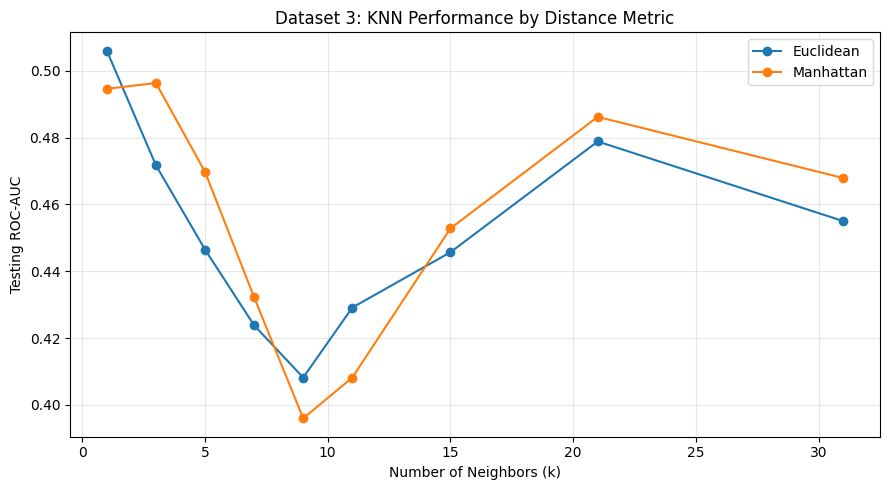

In [22]:
plt.figure(figsize=(9, 5))

for metric in ["euclidean", "manhattan"]:
    subset = k_results3_df[k_results3_df["Distance"] == metric]
    plt.plot(
        subset["K"],
        subset["ROC-AUC"],
        marker="o",
        label=metric.capitalize()
    )

plt.xlabel("Number of Neighbors (k)")
plt.ylabel("Testing ROC-AUC")
plt.title("Dataset 3: KNN Performance by Distance Metric")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

K-Nearest Neighbors algorithm showed poor prediction capability for the dataset “Synthetic B2B CRM & Marketing”. Tuned model with Manhattan distance measure and k = 15 provided an accuracy of 74.15% and ROC-AUC of 0.4528. Despite the improvement in accuracy in comparison with the starting model, KNN classifier could predict only 3 out of 41 inactive contracts, whereas 106 active contracts were predicted perfectly. Various distance measures and number of neighbors used gave varied ROC-AUC scores, suggesting that no improvements due to hyperparameter tuning have been obtained in terms of class discrimination.